# NCO Allocator backtest

Run a trial withe the NCO allocator

Expectations:
- Given the result on the real-world window (two clusters, the calm one holding SHY,
  the Treasuries and the safe-haven currencies), NCO is likely to end up close to
  min_var in terms of risk: volatility around 3.5–4%, drawdown around −12% to −14%
- The book claims NCO has more stable weights than a simple minimum-variance allocator.
  However, ONC re-clusters every month, and if the clusters change, the weights change
  too. Whether turnover ends up below min_var's (6.8%) is difficult to say beforehand
- If NCO behaves like min_var, its daily returns should correlate strongly with
  min_var's (above 0.9), and less with risk_weighted's
- Sharpe: likely in the same range as min_var and HRP (0.45–0.55); any difference is
  expected to be within one standard error

In [8]:
# Imports

import pandas as pd
import numpy as np
from vportfolio import load_data, pipelines, allocators, plotting, trials
from vportfolio.params import TRIALS_LOG, BACKTEST, ROOT
import matplotlib.pyplot as plt

In [2]:
# load data
data = load_data.load_universe()

In [4]:
# run the pipeline with the NCO allocator

# the output will be logged as a potential allocator candidate
# default lookback and CAP apply as per pre-registration
raw_nco = pipelines.trial_pipeline("nco", allocators.nco, "candidate", data)

In [5]:
# now let's compare all strategies so far, side by side

log = pd.read_csv(TRIALS_LOG).set_index("name")
log[["role", "ann_return", "ann_vol", "sharpe", "max_drawdown", "avg_turnover"]]

,role,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover
name,,,,,,
sixty_forty,benchmark,0.082404,0.114335,0.649639,-0.356924,0.021518
equal_weights,benchmark,0.057396,0.100348,0.492381,-0.337178,0.037566
risk_weighted,diagnostic,0.041755,0.052478,0.587724,-0.194149,0.034572
hrp,candidate,0.031254,0.037659,0.532284,-0.116845,0.122157
min_var_raw,candidate,0.025989,0.033743,0.438134,-0.140769,0.070282
min_var_denoised,candidate,0.027114,0.033879,0.468796,-0.139661,0.067720
nco,candidate,0.028294,0.036555,0.468546,-0.096791,0.083309


In [6]:
# print the results in a format that I can copy in markdown files
print(log[["role", "ann_return", "ann_vol", "sharpe", "max_drawdown", "avg_turnover"]].round(3).to_markdown())

| name             | role       |   ann_return |   ann_vol |   sharpe |   max_drawdown |   avg_turnover |
|:-----------------|:-----------|-------------:|----------:|---------:|---------------:|---------------:|
| sixty_forty      | benchmark  |        0.082 |     0.114 |    0.65  |         -0.357 |          0.022 |
| equal_weights    | benchmark  |        0.057 |     0.1   |    0.492 |         -0.337 |          0.038 |
| risk_weighted    | diagnostic |        0.042 |     0.052 |    0.588 |         -0.194 |          0.035 |
| hrp              | candidate  |        0.031 |     0.038 |    0.532 |         -0.117 |          0.122 |
| min_var_raw      | candidate  |        0.026 |     0.034 |    0.438 |         -0.141 |          0.07  |
| min_var_denoised | candidate  |        0.027 |     0.034 |    0.469 |         -0.14  |          0.068 |
| nco              | candidate  |        0.028 |     0.037 |    0.469 |         -0.097 |          0.083 |


Observations: 
- Vol: NCO's volatility is similar to the min-var allocator (3.7% vs 3.4%)
- Dradwown: the lowest drawdown of all strategies, sitting at only -9.7%
- Sharpe: identical to the denoised min-var allocator. The lower volatility does not pay off in returns
- Turnover: the book's stability claim does not seem to hold in the context of this element

In [11]:
# Let's check the correlation vs HRP and min-var
names = ["nco", "min_var_denoised", "hrp", "risk_weighted"]
r = {n: pd.read_parquet(BACKTEST / f"{n}_returns.parquet")[n] for n in names}
pd.DataFrame(r).corr().round(2)

,nco,min_var_denoised,hrp,risk_weighted
nco,1.00,0.88,0.91,0.62
min_var_denoised,0.88,1.00,0.88,0.79
hrp,0.91,0.88,1.00,0.73
risk_weighted,0.62,0.79,0.73,1.00


The correlation forms a tight group with NCO, HRP and min-var; risk-weighted instead sits outside. The two clustering algorithms resemble each other more than either one resembles the min-var allocator. They both reach similar defensive portfolios with different methods.
Risk weighted tends to differ from the other mainly because it is the only one that holds a considerable amount of equities and other riskier assets, which explains a higher Sharpe as well.

Overall, in this universe, the methodology is less important. Once you minimise or balance risk with a 20% CAP, the allocators all converge to roughly the same defensive portfolio and their main difference sits in the drawdown.

**Conclusion:** NCO behaves much like plain minimum variance, with a similar Sharpe
(0.47) and volatility (3.7%), but with the lowest drawdown of all strategies (−9.7% vs
−14.0%). A plausible explanation, not tested here, is that splitting the universe into
two clusters limits how much the optimiser can concentrate in whatever looked safest
just before a sell-off. Its turnover (8.3%) is higher than min_var's, so the expected
gain in stability did not materialise: ONC re-clustering each month moves the weights.
Its daily returns are closest to HRP's (0.91), so the two clustering-based methods
converge on similar defensive portfolios.

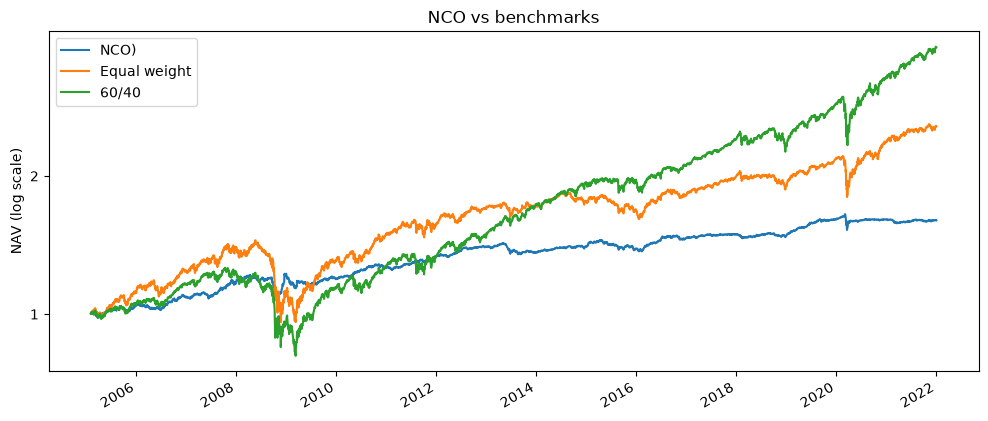

In [9]:
# let's visualize how the allocator's performance changes between raw and denoised inputs

allocators_nav = trials.load_navs(["nco", "equal_weights", "sixty_forty"])

# let's visualize the performance of minimum variance vs benchmark allocators

chart2 = allocators_nav[["nco", "equal_weights", "sixty_forty"]].rename(columns={
    "nco": "NCO)",
    "equal_weights": "Equal weight",
    "sixty_forty": "60/40"})

ax = chart2.plot(logy=True, figsize=(12, 5), title="NCO vs benchmarks")
plotting.format_log_axis(ax)
ax.minorticks_off()
ax.set_ylabel("NAV (log scale)")
ax.set_xlabel("")
plt.show()

In [12]:
# let's save the picture to add it to the  markdown file
ax.figure.savefig(ROOT / "docs" / "figures" / "nco.png", dpi=150, bbox_inches="tight")
plt.show()

The hypothesis, that denoised cluster-based allocation beats equal weight and 60/40 net of costs, is not supported on the research data. What the candidates do deliver is much lower risk. The Denoised Sharpe Ratio (DSR) will allow us to measure whether the best Sharpe is distinguishable from luck.